# Z-Score Regression Analysis — Corrected References

Revisi untuk pemeriksaan Reviewer 2. HAZ menggunakan acuan bulanan panjang badan pada umur 0–23 bulan dan tinggi badan mulai 24 bulan. WAZ menggunakan ekstensi WHO di luar ±3 SD. Umur tepat dalam hari dan posisi pengukuran tidak tersedia.

Enam algoritme dan fitur eksperimen utama dipertahankan. CV acak menjadi dasar pemilihan model; CV berkelompok merupakan pemeriksaan tambahan. Semua hasil ditulis ke `results/regression_corrected/`; eksperimen lama dan naskah Word disimpan. Jeneponto tidak digunakan dalam notebook pelatihan ini.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/icdees-regression-mpl')
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import gc
import hashlib
import json
import time
import platform

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from PIL import Image
from sklearn.model_selection import train_test_split

from analysis.revision import data as data_api
from analysis.revision import supervised as api
from analysis.revision.reviewer2_reference_audit import canonical_reference

ROOT = Path.cwd()
assert (ROOT / 'Stunting_Regression_Analysis.ipynb').exists(), 'Run from repository root'
OUT = ROOT / 'results/regression_corrected'
OUT.mkdir(parents=True, exist_ok=True)
for subdirectory in ['models', 'plots', 'cv']:
    (OUT / subdirectory).mkdir(exist_ok=True)

mpl.rcParams['figure.dpi'] = 500
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman'] + mpl.rcParams['font.serif']
sns.set_theme(style='whitegrid')

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

protected = [ROOT / name for name in ['Stunting_Regression_Analysis.ipynb',
    'Stunting_Classification_Analysis.ipynb', 'Stunting_SHAP_Analysis_Revised.ipynb',
    'analysis/revision/data.py', 'analysis/revision/supervised.py']]
for directory in ['dataset/Stunting Wasting Dataset (Synthetic)', 'dataset/revision',
                  'results/regression', 'results/classification', 'results/shap_revised',
                  'results/revision_1/supervised', 'paper/rev_2_manual']:
    protected.extend(p for p in (ROOT / directory).rglob('*') if p.is_file())
source_hashes = {str(p.relative_to(ROOT)): sha256(p) for p in sorted(set(protected))}
initial_cv_cache = sorted(p.name for p in (OUT / 'cv').glob('*_rf.json'))
print('Separate outputs:', OUT.relative_to(ROOT))
print('Protected input/artifact files:', len(source_hashes))
print('Original plotting font after Seaborn:', mpl.rcParams['font.family'])
print('CV cache present before execution:', initial_cv_cache)


Separate outputs: results/regression_corrected
Protected input/artifact files: 187
Original plotting font after Seaborn: ['sans-serif']
CV cache present before execution: []


## 1. Prepare corrected regression targets

The primary WHO XLSX files are checked against their recorded hashes and rebuilt into the monthly reference table. Original input measurements, row order, sex encoding, and classification labels are retained. No data loader that writes source audit files is called.

In [2]:
DATA_PATH = ROOT / 'dataset/Stunting Wasting Dataset (Synthetic)/stunting_wasting_dataset.csv'
original = pd.read_csv(DATA_PATH).rename(columns={
    'Jenis Kelamin': 'Gender', 'Umur (bulan)': 'Age (months)',
    'Tinggi Badan (cm)': 'Height (cm)', 'Berat Badan (kg)': 'Weight (kg)',
})
original['Gender'] = original['Gender'].replace({'Laki-laki': 'Male', 'Perempuan': 'Female'})
original['Gender_Encoded'] = original['Gender'].map({'Female': 0, 'Male': 1})
original['Source_Row'] = np.arange(1, len(original) + 1)
reference, reference_manifest = canonical_reference()
frame = data_api._enrich(original, reference, corrected=True)
legacy = data_api._enrich(original, data_api._legacy_references(ROOT), corrected=False)
assert len(frame) == 100000 and frame.index.equals(pd.RangeIndex(100000))
pd.testing.assert_frame_equal(frame[api.FEATURES['classification']], original[api.FEATURES['classification']])
pd.testing.assert_series_equal(frame.Stunting, original.Stunting)
assert np.isfinite(frame[api.FEATURES['classification'] + ['HAZ', 'WAZ']].to_numpy()).all()
changes = []
for task in ['HAZ', 'WAZ']:
    changed = np.abs(frame[task].to_numpy() - legacy[task].to_numpy()) > 1e-12
    changes.append({'target': task, 'changed_records': int(changed.sum()),
                    'changed_below_24': int((changed & (frame['Age (months)'] < 24)).sum()),
                    'changed_age_24': int((changed & (frame['Age (months)'] == 24)).sum())})
assert [row['changed_records'] for row in changes] == [3954, 22063]
pd.DataFrame(changes).to_csv(OUT / 'target_changes.csv', index=False)
display(pd.DataFrame(changes))


,target,changed_records,changed_below_24,changed_age_24
0,HAZ,3954,0,3954
1,WAZ,22063,21601,462


## 2. Six-model cross-validation

Both protocols are computed in this separate output directory. An exact rerun can resume matching caches, which are identified by input/target/parameter and fold fingerprints. On the first execution all 120 fits are fresh. Training time is measured within each five-fold run using four workers; historical notebook times are not reused. Grouped folds separate identical sex–age–height profiles for HAZ and sex–age–weight profiles for WAZ.

In [3]:
cv_results = []
for protocol in ['random', 'grouped']:
    for task in ['HAZ', 'WAZ']:
        cv_results.extend(api.evaluate(frame, task, api.REG_NAMES, protocol, 'corrected', OUT))

metric_rows, reproduced = [], []
for result in cv_results:
    metric_rows.append({'protocol': result['protocol'], 'reference': result['reference'],
        'task': result['task'], 'model': result['model'],
        **result['mean'], **{f'{key}_sd': value for key, value in result['sd'].items()},
        'training_seconds_5_folds': result['training_seconds']})
    historical_path = ROOT / 'results/revision_1/supervised/cv' / (
        f"corrected_{result['protocol']}_{result['task']}_{api.CODES[result['model']]}.json")
    historical = json.loads(historical_path.read_text())
    assert historical['fingerprint'] == result['fingerprint']
    error = max(abs(historical['folds'][i][key] - result['folds'][i][key])
                for i in range(5) for key in ['mae', 'rmse', 'r2'])
    assert error < 1e-8, (historical_path, error)
    reproduced.append({'protocol': result['protocol'], 'task': result['task'],
                       'model': result['model'], 'maximum_fold_metric_difference': error})
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUT / 'cv_metrics.csv', index=False)
pd.DataFrame(reproduced).to_csv(OUT / 'historical_cache_reproduction.csv', index=False)
selected = {}
for task in ['HAZ', 'WAZ']:
    comparison = metrics[(metrics.protocol == 'random') & (metrics.task == task)].sort_values('rmse')
    selected[task] = str(comparison.iloc[0]['model'])
    assert selected[task] == 'Random Forest'
    print(task, 'selected by primary random CV:', selected[task])
display(metrics)


CV corrected/random/HAZ/Linear Regression fold 1/5 0.03s
CV corrected/random/HAZ/Linear Regression fold 2/5 0.01s
CV corrected/random/HAZ/Linear Regression fold 3/5 0.01s
CV corrected/random/HAZ/Linear Regression fold 4/5 0.02s
CV corrected/random/HAZ/Linear Regression fold 5/5 0.02s
CV corrected/random/HAZ/Ridge Regression fold 1/5 0.03s
CV corrected/random/HAZ/Ridge Regression fold 2/5 0.01s
CV corrected/random/HAZ/Ridge Regression fold 3/5 0.01s
CV corrected/random/HAZ/Ridge Regression fold 4/5 0.01s
CV corrected/random/HAZ/Ridge Regression fold 5/5 0.01s
CV corrected/random/HAZ/Random Forest fold 1/5 0.68s
CV corrected/random/HAZ/Random Forest fold 2/5 0.58s
CV corrected/random/HAZ/Random Forest fold 3/5 0.82s
CV corrected/random/HAZ/Random Forest fold 4/5 0.95s
CV corrected/random/HAZ/Random Forest fold 5/5 0.73s
CV corrected/random/HAZ/XGBoost fold 1/5 0.21s
CV corrected/random/HAZ/XGBoost fold 2/5 0.18s
CV corrected/random/HAZ/XGBoost fold 3/5 0.22s
CV corrected/random/HAZ/XGBoo

,protocol,reference,task,model,mae,rmse,r2,mae_sd,rmse_sd,r2_sd,training_seconds_5_folds
0,random,corrected,HAZ,Linear Regression,0.620085,0.838195,0.819075,0.002690,0.006314,3.029050e-03,0.094045
1,random,corrected,HAZ,Ridge Regression,0.620084,0.838195,0.819075,0.002690,0.006314,3.029022e-03,0.076480
2,random,corrected,HAZ,Random Forest,0.000106,0.000800,1.000000,0.000001,0.000095,3.948759e-08,3.752243
3,random,corrected,HAZ,XGBoost,0.042182,0.056867,0.999167,0.000979,0.001219,3.525695e-05,1.038633
4,random,corrected,HAZ,LightGBM,0.075523,0.097712,0.997540,0.001668,0.002315,1.201689e-04,1.219357
5,random,corrected,HAZ,CatBoost,0.026599,0.040761,0.999572,0.000154,0.000384,7.156920e-06,27.453527
6,random,corrected,WAZ,Linear Regression,0.596451,0.856616,0.860509,0.002300,0.005276,1.780331e-03,0.045259
7,random,corrected,WAZ,Ridge Regression,0.596451,0.856616,0.860509,0.002300,0.005276,1.780349e-03,0.056549
8,random,corrected,WAZ,Random Forest,0.000002,0.000136,1.000000,0.000001,0.000070,3.222706e-09,3.424557
9,random,corrected,WAZ,XGBoost,0.029302,0.039490,0.999703,0.000536,0.000988,1.447650e-05,0.893196


## 3. Fit the original 80:20 split and freeze models

Each regressor is fitted on the same 80,000 synthetic training rows as the original experiment. The existing RF classifier is retained. The 20,000 rows are held out from these particular fits, but participated in model-selection CV; they are used here for plots/SHAP, not claimed as an independent selection holdout. The three selected model hashes are frozen before external evaluation.

In [4]:
train_rows, test_rows = train_test_split(frame.index.to_numpy(), test_size=0.2, random_state=42)
assert len(train_rows) == 80000 and len(test_rows) == 20000
assert not np.intersect1d(train_rows, test_rows).size
np.savez_compressed(OUT / 'split_indices.npz', train_row_index=train_rows, test_row_index=test_rows)
models, predictions, holdout_rows, fit_times = {}, {}, [], {}
for task in ['HAZ', 'WAZ']:
    X, y = frame[api.FEATURES[task]], frame[task]
    prediction_table = pd.DataFrame({'Source_Row': frame.loc[test_rows, 'Source_Row'].to_numpy(),
                                    'target': y.loc[test_rows].to_numpy()})
    for name in api.REG_NAMES:
        model = api.create_model(task, name)
        started = time.perf_counter()
        model.fit(X.loc[train_rows], y.loc[train_rows])
        elapsed = time.perf_counter() - started
        prediction = np.asarray(model.predict(X.loc[test_rows])).ravel()
        model_path = OUT / 'models' / f'stunting_{name.lower().replace(" ", "_")}_reg_{task.lower()}.joblib'
        joblib.dump(model, model_path)
        models[(task, name)] = model
        predictions[(task, name)] = prediction
        fit_times[f'{task}/{name}'] = elapsed
        holdout_rows.append({'task': task, 'model': name,
            **api.regression_metrics(y.loc[test_rows], prediction), 'fit_seconds': elapsed})
        prediction_table[name] = prediction
        print('HOLDOUT FIT', task, name, f'{elapsed:.2f}s', flush=True)
    prediction_table.to_csv(OUT / f'holdout_predictions_{task}.csv', index=False)
pd.DataFrame(holdout_rows).to_csv(OUT / 'holdout_metrics.csv', index=False)

classifier_path = ROOT / 'results/classification/stunting_random_forest_classifier.joblib'
classifier = joblib.load(classifier_path)
assert classifier.feature_names_in_.tolist() == api.FEATURES['classification']
assert classifier.classes_.tolist() == [0, 1, 2, 3]
assert classifier.n_estimators == 50 and classifier._n_samples == 80000
assert classifier.class_weight == 'balanced' and classifier.random_state == 42
target_encoder = joblib.load(ROOT / 'results/classification/stunting_target_encoder.joblib')
assert target_encoder.classes_.tolist() == api.CLASSES
training_y = target_encoder.transform(frame.loc[train_rows, 'Stunting'])
class_counts = np.bincount(training_y, minlength=4)
class_weights = len(training_y) / (4 * class_counts)
classifier_root_errors = []
for i, tree in enumerate(classifier.estimators_):
    labels = training_y[classifier.estimators_samples_[i]]
    weighted = np.bincount(labels, weights=class_weights[labels], minlength=4)
    error = float(np.max(np.abs(tree.tree_.value[0, 0] - weighted / weighted.sum())))
    assert error < 1e-10
    classifier_root_errors.append(error)

model_entries = {}
for task in ['HAZ', 'WAZ', 'classification']:
    if task == 'classification':
        model, path = classifier, classifier_path
    else:
        model = models[(task, selected[task])]
        path = OUT / 'models' / f'stunting_random_forest_reg_{task.lower()}.joblib'
        assert model._n_samples == len(train_rows)
        target_train = frame.loc[train_rows, task].to_numpy()
        for i, tree in enumerate(model.estimators_):
            expected = target_train[model.estimators_samples_[i]].mean()
            np.testing.assert_allclose(tree.tree_.value[0, 0, 0], expected, rtol=0, atol=1e-10)
    model_entries[task] = {'path': str(path.relative_to(ROOT)), 'sha256': sha256(path),
        'features': api.FEATURES[task], 'class': type(model).__name__,
        'parameters': api.serializable_parameters(model.get_params()), 'training_rows': len(train_rows)}

freeze = {'frozen_at_utc': datetime.now(timezone.utc).isoformat(),
    'selection_basis': 'Primary random five-fold CV on synthetic data; grouped CV supplementary; external data not used',
    'training_data': {'path': str(DATA_PATH.relative_to(ROOT)), 'sha256': sha256(DATA_PATH)},
    'reference': {'path': 'dataset/revision/references/who_monthly_corrected.csv',
                  'sha256': reference_manifest['corrected_sha256'],
                  'convention': reference_manifest['convention'], 'waz_tail': reference_manifest['waz_tail']},
    'training_split': {'rows': len(frame), 'training_rows': len(train_rows), 'test_rows': len(test_rows),
        'test_size': 0.2, 'random_state': 42, 'stratify': None,
        'train_indices_sha256': hashlib.sha256(train_rows.tobytes()).hexdigest(),
        'test_indices_sha256': hashlib.sha256(test_rows.tobytes()).hexdigest()},
    'models': model_entries, 'classification_class_mapping': {str(i): name for i, name in enumerate(api.CLASSES)},
    'external_protocol': {'primary_age_months': [0, 23], 'supplementary_age_months': [24, 24],
        'classification_decision': 'Original four-class argmax, then Severe/Stunted vs Normal/Tall',
        'classification_reference': 'Preserved source binary label',
        'regression_reference': 'Recomputed corrected monthly HAZ/WAZ; not independent clinical outcomes',
        'external_data_used_for_fitting_or_selection': False},
    'versions': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost', 'joblib']}}
api.write_json(OUT / 'model_freeze_manifest.json', freeze)
print('FROZEN:', OUT / 'model_freeze_manifest.json', flush=True)


HOLDOUT FIT HAZ Linear Regression 0.01s
HOLDOUT FIT HAZ Ridge Regression 0.01s
HOLDOUT FIT HAZ Random Forest 0.76s
HOLDOUT FIT HAZ XGBoost 0.27s
HOLDOUT FIT HAZ LightGBM 0.24s
HOLDOUT FIT HAZ CatBoost 4.98s
HOLDOUT FIT WAZ Linear Regression 0.02s
HOLDOUT FIT WAZ Ridge Regression 0.02s
HOLDOUT FIT WAZ Random Forest 0.61s
HOLDOUT FIT WAZ XGBoost 0.18s
HOLDOUT FIT WAZ LightGBM 0.25s
HOLDOUT FIT WAZ CatBoost 4.76s
FROZEN: /home/haerulyudaaditiya/Documents/sscs/exp_interpretable_ml/results/regression_corrected/model_freeze_manifest.json


## 4. Actual versus predicted — original figure style

The two paper figures keep the original six-panel layout, scatter styling, axis labels, identity lines, and export settings. Data and fitted regressors use the corrected targets.

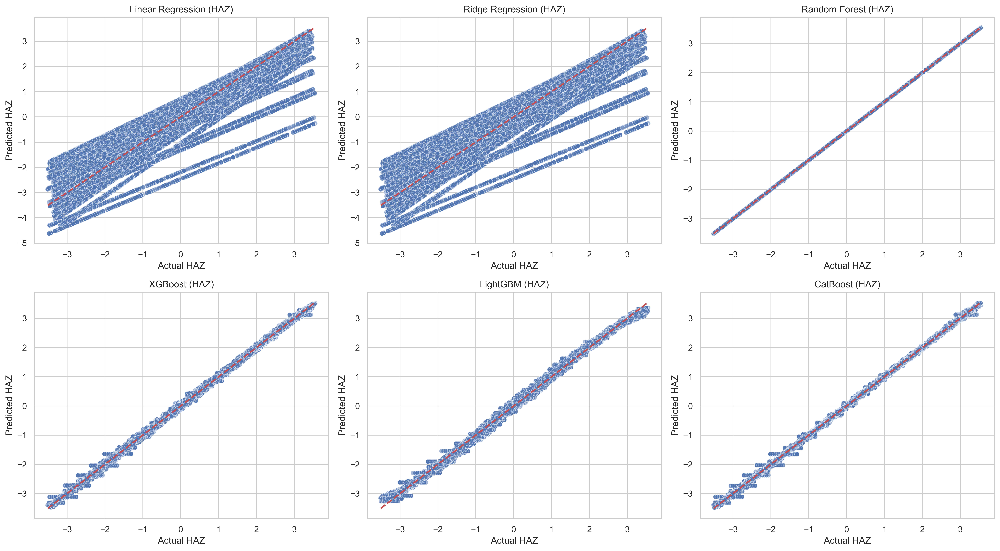

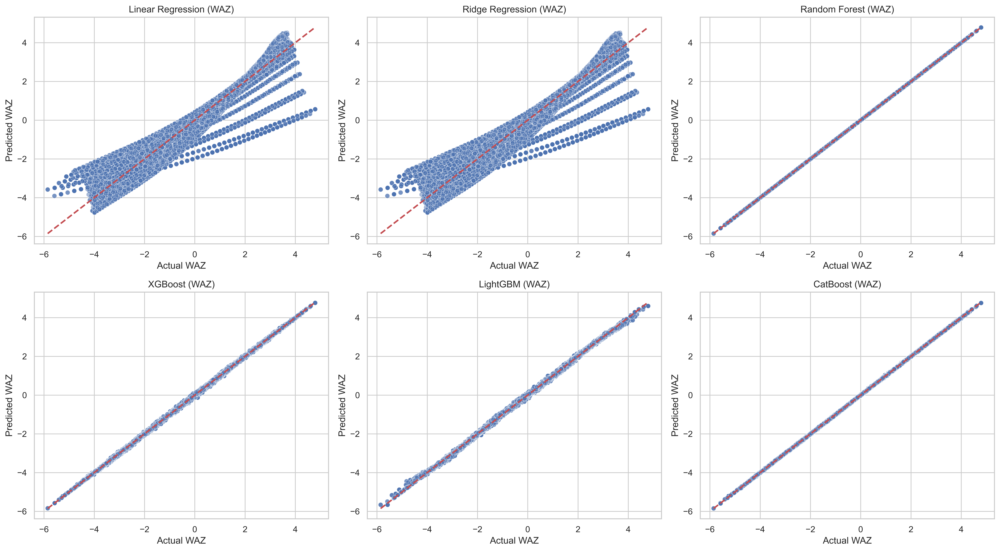

In [5]:
plot_metadata = {}
def save_figure(stem):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(OUT / 'plots' / f'{stem}.png', dpi=500, bbox_inches='tight')
    fig.savefig(OUT / 'plots' / f'{stem}.pdf', dpi=500, bbox_inches='tight')
    with Image.open(OUT / 'plots' / f'{stem}.png') as image:
        pixels = list(image.size)
    plot_metadata[stem] = {'figure_inches': fig.get_size_inches().tolist(),
        'png_pixels': pixels, 'dpi': 500, 'font_family': list(mpl.rcParams['font.family'])}
    plt.show()
    plt.close(fig)
    gc.collect()

for task in ['HAZ', 'WAZ']:
    actual = frame.loc[test_rows, task]
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=500)
    for ax, name in zip(axes.flatten(), api.REG_NAMES):
        sns.scatterplot(x=actual, y=predictions[(task, name)], alpha=0.5, ax=ax)
        ax.plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'r--', lw=2)
        ax.set_title(f'{name} ({task})')
        ax.set_xlabel(f'Actual {task}')
        ax.set_ylabel(f'Predicted {task}')
    save_figure(f'scatter_combined_{task.lower()}')


## 5. SHAP of the corrected Random Forest regressors

The original 500 regression sample indices and plot style are retained. All sample rows are checked against the fit holdout. TreeSHAP explains these exact saved models on the Z-score scale; associations are not causal effects.

SHAP HAZ max additivity error: 1.829647544582258e-13
SHAP WAZ max additivity error: 1.5543122344752192e-13


<ipython-input-1-bf7bddeac216>:34: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False, plot_size=None)
<ipython-input-1-bf7bddeac216>:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanations['WAZ'], samples['WAZ'], show=False, plot_size=None)


,task,rank,feature,mean_absolute_shap
0,HAZ,1,Height (cm),1.475480
1,HAZ,2,Age (months),1.135588
2,HAZ,3,Gender_Encoded,0.268985
3,WAZ,1,Weight (kg),1.808071
4,WAZ,2,Age (months),1.102586
5,WAZ,3,Gender_Encoded,0.237575


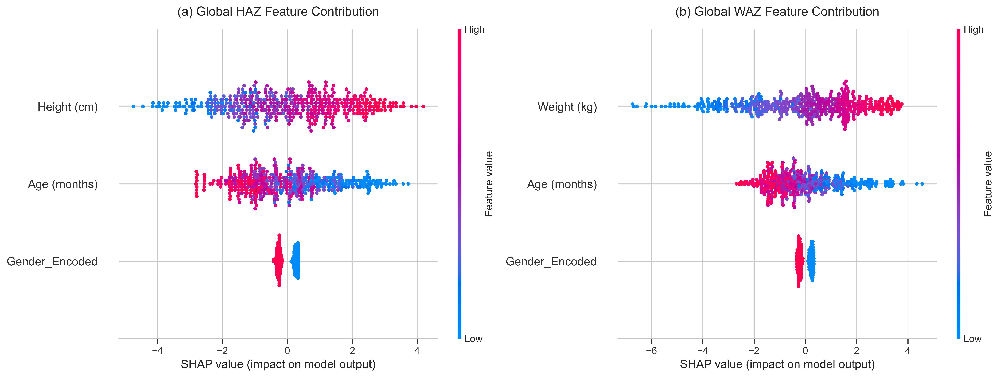

In [6]:
samples, explanations, errors, shap_seconds = {}, {}, {}, {}
importance_rows = []
arrays = {}
for task in ['HAZ', 'WAZ']:
    sample = frame[api.FEATURES[task]].sample(500, random_state=42)
    assert sample.index.isin(test_rows).all()
    saved_model = joblib.load(ROOT / freeze['models'][task]['path'])
    assert sha256(ROOT / freeze['models'][task]['path']) == freeze['models'][task]['sha256']
    started = time.perf_counter()
    explanation = shap.TreeExplainer(saved_model, feature_perturbation='tree_path_dependent',
                                    model_output='raw')(sample, approximate=False, check_additivity=True)
    prediction = saved_model.predict(sample)
    reconstructed = explanation.base_values + explanation.values.sum(axis=1)
    np.testing.assert_allclose(reconstructed, prediction, rtol=0, atol=1e-7)
    samples[task], explanations[task] = sample, explanation
    errors[task] = float(np.max(np.abs(reconstructed - prediction)))
    shap_seconds[task] = time.perf_counter() - started
    for rank, i in enumerate(np.argsort(-np.abs(explanation.values).mean(axis=0)), 1):
        importance_rows.append({'task': task, 'rank': rank, 'feature': api.FEATURES[task][i],
                               'mean_absolute_shap': float(np.abs(explanation.values[:, i]).mean())})
    arrays.update({f'{task}_row_index': sample.index.to_numpy(), f'{task}_inputs': sample.to_numpy(),
                   f'{task}_shap': explanation.values, f'{task}_base': explanation.base_values,
                   f'{task}_prediction': prediction})
    print('SHAP', task, 'max additivity error:', errors[task], flush=True)
assert samples['HAZ'].index.equals(samples['WAZ'].index)
np.savez_compressed(OUT / 'explanations.npz', **arrays)
importance = pd.DataFrame(importance_rows)
importance.to_csv(OUT / 'feature_importance.csv', index=False)
display(importance)

np.random.seed(42)
fig = plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False, plot_size=None)
plt.title('(a) Global HAZ Feature Contribution', fontsize=14, pad=15)
plt.subplot(1, 2, 2)
shap.summary_plot(explanations['WAZ'], samples['WAZ'], show=False, plot_size=None)
plt.title('(b) Global WAZ Feature Contribution', fontsize=14, pad=15)
save_figure('shap_summary_komparasi')


## 6. Verify provenance and preserve the original artifacts

In [7]:
unchanged = {path: sha256(ROOT / path) == value for path, value in source_hashes.items()}
assert all(unchanged.values()), [path for path, same in unchanged.items() if not same]
for task, entry in freeze['models'].items():
    assert sha256(ROOT / entry['path']) == entry['sha256'], task
summary = {'purpose': 'Corrected regression training and supplementary validation for Reviewer 2',
    'targets': changes, 'selection': selected, 'selection_basis': freeze['selection_basis'],
    'cv_metrics': metrics.to_dict(orient='records'), 'initial_rf_cv_cache': initial_cv_cache,
    'historical_cache_reproduction': reproduced,
    'holdout_fit_metrics': holdout_rows, 'split': freeze['training_split'],
    'plots': plot_metadata, 'shap_ranking': importance_rows, 'shap_seconds': shap_seconds,
    'model_freeze_manifest': 'results/regression_corrected/model_freeze_manifest.json',
    'python': platform.python_version(),
    'versions': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm',
                                        'catboost', 'shap', 'matplotlib', 'seaborn', 'joblib']},
    'limitations': ['Monthly ages, assumed length/height convention; measurement position unavailable',
        'Synthetic targets are deterministic reference calculations from the inputs',
        'Random CV contains repeated input profiles across folds',
        'Grouped WAZ ranks CatBoost above RF; selected RF follows primary random CV only',
        'Fit-held-out SHAP rows participated in model-selection CV',
        'These regression scores do not establish independent clinical validity',
        'No external outcomes are used here; dashboard and Word are not modified']}
api.write_json(OUT / 'summary.json', summary)
api.write_json(OUT / 'verification.json', {'source_sha256': source_hashes,
    'sources_unchanged': unchanged, 'max_shap_additivity_error': errors, 'shap_tolerance': 1e-7,
    'classifier_bootstrap_root_max_error': max(classifier_root_errors),
    'all_shap_sample_rows_fit_held_out': True,
    'output_sha256': {str(p.relative_to(OUT)): sha256(p) for p in sorted(OUT.rglob('*'))
                      if p.is_file() and p.name not in ['verification.json', 'CATATAN_HASIL.md', 'PROTOKOL.md']}})
print('Verified: corrected targets, fresh/matching CV, exact saved models, SHAP additivity, and source integrity.')
print('External evaluation is a separate step using the frozen manifest.')


Verified: corrected targets, fresh/matching CV, exact saved models, SHAP additivity, and source integrity.
External evaluation is a separate step using the frozen manifest.
